In [1]:
%pip install -q --disable-pip-version-check -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


1. Данные
Источник - [README](README.md). Одна строка - одно действие в магазине косметики в октябре 2019 года.

`user_id`, `product_id` - пользователь и товар; `event_time` - время UTC; `event_type` - действие; `category_id`, `category_code` - категория; `brand` - бренд; `price` - цена; `user_session` - сессия.

Рекомендуем 10 новых товаров. Считаем товар подходящим, если его добавили в корзину или купили. Последующее удаление из корзины это не меняет.

До обработки: 4 102 283 события, 399 664 пользователя, 41 899 товаров. После: 809 772 события, 12 000 пользователей, 3 000 товаров.

In [2]:
import os

for name in ['OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS']:
    os.environ[name] = '1'

In [3]:
from pathlib import Path
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from models.item_knn import ItemKNN
from models.ials import ImplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_als import CustomTargetALS
from scipy import sparse

In [4]:
np.seterr(divide="raise", over="raise", invalid="raise")

date1 = pd.Timestamp('2019-10-21', tz='UTC')
date2 = pd.Timestamp('2019-10-26', tz='UTC')

kinds = ['view', 'cart', 'purchase', 'remove_from_cart']

In [5]:
seed = 42
pd.set_option('display.max_colwidth', None)

In [6]:
path = Path('cache/2019-Oct.csv')

if not path.exists():
    path.parent.mkdir(exist_ok=True)
    url = 'https://www.kaggle.com/api/v1/datasets/download/mkechinov/ecommerce-events-history-in-cosmetics-shop/2019-Oct.csv'
    urllib.request.urlretrieve(url, 'cache/october.zip')

    with zipfile.ZipFile('cache/october.zip') as z:
        z.extract('2019-Oct.csv', 'cache')

In [7]:
df = pd.read_csv(path)

gaps = df.isna().mean()
totals = df.event_type.value_counts()

stats = {
    'События до очистки': len(df),
    'Пользователи до очистки': df.user_id.nunique(),
    'Товары до очистки': df.product_id.nunique(),
    'Дубликаты': df.duplicated().sum()
}

2. Подготовка данных
Убираем одинаковые строки, строки без ID или времени и неизвестные типы действий. Действия в разное время оставляем. Цену 0 и ниже считаем пропуском. Пропущенный бренд помечаем отдельно.

По данным за 1-20 октября берём 3000 товаров с наибольшим числом пользователей. Затем берём 12 000 пользователей с наибольшим числом разных выбранных товаров. При равенстве берём меньший ID. Эти товары и пользователи остаются на весь месяц. Так EASE требует меньше памяти, но в данных больше активных пользователей и популярных товаров.

In [8]:
df = df.drop_duplicates().copy()
df.event_time = pd.to_datetime(df.event_time, utc=True, errors='coerce')
df = df.dropna(subset=['user_id', 'product_id', 'event_time'])
df = df[df.event_type.isin(kinds)].copy()


df.loc[df.price <= 0, 'price'] = np.nan
df['brand'] = df.brand.fillna('__unknown__')
df['category_id'] = df.category_id.fillna(-1).astype(str)

stats['После очистки'] = len(df)

In [9]:
hist = df[df.event_time < date1]

pop = hist.groupby('product_id').user_id.nunique()
pop = pop.sort_values(ascending=False, kind='stable')
i_ids = np.sort(pop.head(3000).index)

item_hist = hist[hist.product_id.isin(i_ids)]
act = item_hist.groupby('user_id').product_id.nunique()
act = act.sort_values(ascending=False, kind='stable')
u_ids = np.sort(act.head(12000).index)

In [10]:
keep_i = df.product_id.isin(i_ids)
keep_u = df.user_id.isin(u_ids)
data = df[keep_i & keep_u].copy()

data['u'] = np.searchsorted(u_ids, data.user_id)
data['i'] = np.searchsorted(i_ids, data.product_id)

sort_by = ['event_time', 'u', 'i', 'event_type']
data = data.sort_values(sort_by, kind='stable')
data = data.reset_index(drop=True)

In [11]:
size = (len(u_ids), len(i_ids))
pairs = data[['u', 'i']].drop_duplicates()
empty = 1 - len(pairs) / (size[0] * size[1])

stats['События в выборке'] = len(data)
stats['Пользователи в выборке'] = size[0]
stats['Товары в выборке'] = size[1]
stats['Разные пары пользователь-товар'] = len(pairs)
stats['Доля пар без действий'] = empty

assert 100_000 <= len(data) <= 2_000_000
assert size[0] >= 1000 and size[1] >= 1000

display(pd.Series(stats, name='Значение'))

События до очистки                4.102283e+06
Пользователи до очистки           3.996640e+05
Товары до очистки                 4.189900e+04
Дубликаты                         2.131550e+05
После очистки                     3.889128e+06
События в выборке                 8.097720e+05
Пользователи в выборке            1.200000e+04
Товары в выборке                  3.000000e+03
Разные пары пользователь-товар    3.891890e+05
Доля пар без действий             9.891892e-01
Name: Значение, dtype: float64

In [12]:
display(gaps.to_frame('Доля пропусков'))
display(totals.to_frame('События до очистки'))

,Доля пропусков
event_time,0.000000
event_type,0.000000
product_id,0.000000
category_id,0.000000
category_code,0.983551
brand,0.404473
price,0.000000
user_id,0.000000
user_session,0.000155


,События до очистки
event_type,
view,1862164
cart,1232385
remove_from_cart,762110
purchase,245624


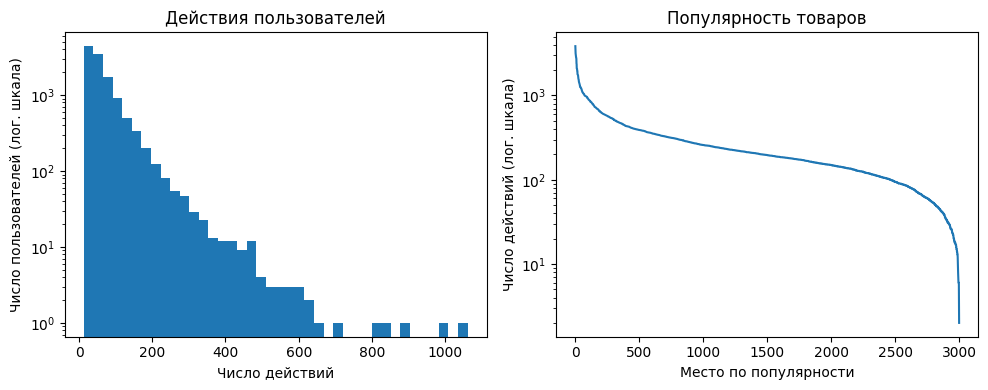

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

act = data.groupby('u').size()
ax[0].hist(act, bins=40, log=True)
ax[0].set(title='Действия пользователей', xlabel='Число действий', ylabel='Число пользователей (лог. шкала)')

pop = data.groupby('i').size().sort_values(ascending=False)
ax[1].plot(pop.to_numpy())
ax[1].set(title='Популярность товаров', xlabel='Место по популярности', ylabel='Число действий (лог. шкала)', yscale='log')

plt.tight_layout()
plt.show()

In [14]:
train = data[data.event_time < date1].copy()
val = data[(data.event_time >= date1) & (data.event_time < date2)].copy()

In [15]:
display(pd.Series({
    'Категорий в train': train.category_id.nunique(),
    'Брендов в train': train.loc[train.brand != '__unknown__', 'brand'].nunique(),
    'Медиана цены': train.price.median()
}))

Категорий в train    276.00
Брендов в train      102.00
Медиана цены           3.49
dtype: float64

Признаки товаров на конец train.

In [16]:
meta = train.drop_duplicates('i', keep='last')

filled = pd.Series({
    'Категория': meta.category_id.ne('-1').mean(),
    'Бренд': meta.brand.ne('__unknown__').mean(),
    'Цена': meta.price.notna().mean()
}) * 100

In [17]:
display(filled.to_frame('Есть данные, %'))

,"Есть данные, %"
Категория,100.000000
Бренд,59.006004
Цена,100.000000


3. Оценка качества
Train - 1-20 октября, validation - 21-25, test - 26-31. Время UTC. На train обучаем, на validation выбираем настройки. Затем обучаем на train + validation. Используем только признаки, известные до рекомендации.

Выбираем из всех товаров выборки, с которыми пользователь ещё не взаимодействовал. Уже известные товары убираем и из правильных ответов. Новых пользователей и товары вне выборки не оцениваем. Берём пользователей, у которых есть новый товар в корзине или покупках. Для всех моделей пользователи, товары и правильные ответы одинаковые. При равных оценках первым идёт меньший ID.

NDCG@10 - главная метрика. Чем выше подходящий товар в списке, тем лучше:
$$DCG@10=\sum_{r=1}^{10}\frac{rel_r}{\log_2(r+1)},\qquad NDCG@10=\frac{DCG@10}{\sum_{r=1}^{\min(10,|R_u|)}1/\log_2(r+1)}.$$
Вторая метрика - Recall@10: $|Top10_u\cap R_u|/|R_u|$, доля подходящих товаров, попавших в top-10. Обе метрики усредняем по пользователям.

In [18]:
def matrices(hist, size, date):
    acts = hist.groupby(['u', 'i', 'event_type']).size().unstack(fill_value=0)
    acts = acts.reindex(columns=kinds, fill_value=0)
    u = acts.index.get_level_values('u')
    i = acts.index.get_level_values('i')

    x = sparse.csr_matrix((acts.sum(axis=1), (u, i)), shape=size, dtype=float)
    p = x.copy()
    p.data = (acts[['view', 'cart', 'purchase']].sum(axis=1) > 0).to_numpy(float)

    last_time = hist.groupby(['u', 'i']).event_time.max()
    days = (date - last_time).dt.total_seconds().to_numpy() / 86400

    return {'counts': x, 'preferences': p, 'events': acts, 'ages': days}

In [19]:
def make_truth(future, past):
    good = future[future.event_type.isin(['cart', 'purchase'])]
    good = good[['u', 'i']].drop_duplicates()
    seen = np.asarray(past[good.u, good.i]).ravel() > 0
    good = good[~seen]

    return good.groupby('u').i.apply(set).to_dict()

In [20]:
def recommend(model, u, past):
    scores = model.score(u)

    if not np.isfinite(scores).all():
        raise FloatingPointError("Non-finite scores before ranking")

    used = past[u].tocoo()
    scores[used.row, used.col] = -np.inf

    return np.argsort(-scores, axis=1, kind='stable')[:, :10]

In [21]:
def evaluate(model, target, past):
    u = sorted(target)
    w = 1 / np.log2(np.arange(2, 12))
    ndcg, recall = [], []

    for start in range(0, len(u), 128):
        batch = u[start:start + 128]
        top10 = recommend(model, batch, past)

        for uid, recs in zip(batch, top10):
            good = target[uid]
            hits = np.isin(recs, list(good))
            dcg = (hits * w).sum()
            max_dcg = w[:min(10, len(good))].sum()

            ndcg.append(dcg / max_dcg)
            recall.append(hits.sum() / len(good))

    return np.mean(ndcg), np.mean(recall)

In [22]:
train_m = matrices(train, size, date1)
val_y = make_truth(val, train_m['counts'])

print('Train / validation:', len(train), len(val))
print('Пользователи в validation:', len(val_y))

assert train.event_time.max() < val.event_time.min()

Train / validation: 679017 66996
Пользователи в validation: 2164


4. Модели и настройки

$X_{ui}=1$, если был просмотр, корзина или покупка; иначе 0. $n_{ui}$ - число действий пары. $\lambda$ - регуляризация.

ItemKNN. Сходство товаров:

$$s_{ij}=\frac{X_{:i}^TX_{:j}}{\|X_{:i}\|\|X_{:j}\|+\gamma},\qquad s_{ii}=0.$$

Оставляем $k$ соседей. Оценка товара: $\sum_jX_{uj}s_{ji}$. $\gamma$ уменьшает ненадёжное сходство.

iALS. $p_{ui}=X_{ui}$, $c_{ui}=1+\alpha\log(1+n_{ui})$. Для неизвестных пар $p=0,c=1$. По очереди обучаем векторы пользователей и товаров:

$$\min_{A,B}\sum_{ui}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$

EASE. Обучаем связи между товарами, оценки равны $XW$:

$$\min_{\operatorname{diag}(W)=0}\|X-XW\|_F^2+\lambda\|W\|_F^2.$$

FM. Учитываем отдельные признаки и их пары:

$$f(z)=w_0+\sum_jw_jz_j+\sum_{j<l}\langle v_j,v_l\rangle z_jz_l.$$

Признаки: ID пользователя и товара, категория, бренд и группа по цене. Категория и бренд связывают похожие товары, цена помогает различать дешёвые и дорогие. Берём последние значения до рекомендации. Обучаем с логистической ошибкой, L2 и Adagrad. На каждую пару с меткой 1 добавляем два неизвестных товара с меткой 0.

CustomALS. Заменяем цель $p$ на $q$. Веса $c$ и способ обучения остаются как у iALS:

$$q_{ui}=\tanh\left(\frac{\log(1+n^{view}_{ui})+2\log(1+n^{cart}_{ui})+4\log(1+n^{purchase}_{ui})-2\log(1+n^{remove}_{ui})}{3}\right)2^{-d_{ui}/14}.$$

$d_{ui}$ - дни с последнего действия. Покупка увеличивает оценку, удаление и давность уменьшают. Log и tanh снижают влияние повторов. Веса заданы заранее. Для неизвестных пар $q=0$.

Пробуем два набора настроек из `search`. Берём лучший по NDCG@10 на validation. При равенстве берём первый.

In [23]:
def features(hist, size):
    nu, ni = size
    last = hist.drop_duplicates('i', keep='last').set_index('i')
    last = last.reindex(range(ni))

    f = [nu + np.arange(ni)]
    shift = nu + ni

    for col in ['category_id', 'brand']:
        vals = last[col].fillna('__unknown__').astype(str)
        ids, cats = pd.factorize(vals, sort=True)
        f.append(ids + shift)
        shift += len(cats)

    prices = np.digitize(last.price.fillna(-1), [0, 2, 5, 10, 20, 50, 100])
    f.append(prices + shift)

    return np.column_stack(f)

In [24]:
def training_examples(m):
    rng = np.random.default_rng(seed)
    past = m['counts']
    u, i = m['preferences'].nonzero()
    assert (past.getnnz(axis=1) < past.shape[1]).all()

    neg_u = np.repeat(u, 2)
    neg_i = rng.integers(past.shape[1], size=len(neg_u))
    seen = np.asarray(past[neg_u, neg_i]).ravel() > 0

    while seen.any():
        neg_i[seen] = rng.integers(past.shape[1], size=seen.sum())
        seen = np.asarray(past[neg_u, neg_i]).ravel() > 0

    y = np.concatenate([np.ones(len(u)), np.zeros(len(neg_u))])
    u = np.concatenate([u, neg_u])
    i = np.concatenate([i, neg_i])

    return u, i, y

In [25]:
search = {
    'ItemKNN': [dict(neighbors=30, shrinkage=10.), dict(neighbors=100, shrinkage=50.)],
    'iALS': [dict(factors=24, regularization=1.), dict(factors=40, regularization=10.)],
    'EASE': [dict(regularization=50.), dict(regularization=300.)],
    'FM': [dict(factors=16, regularization=.0001), dict(factors=24, regularization=.001)]
}
search['CustomALS'] = search['iALS']

In [26]:
def fit_model(name, params, hist, m, sample):
    x = m['counts']
    p = m['preferences']

    if name == 'ItemKNN':
        return ItemKNN(**params).fit(p)

    if name == 'EASE':
        return EASE(**params).fit(p)

    if name == 'iALS':
        model = ImplicitALS(**params, seed=seed)
        return model.fit(x, p)

    if name == 'CustomALS':
        model = CustomTargetALS(**params, seed=seed)
        return model.fit(x, m['events'], m['ages'])

    u, i, y = sample
    model = FactorizationMachine(**params, seed=seed)
    return model.fit(u, i, y, features(hist, size), size[0])

In [27]:
train_xy = training_examples(train_m)
best_params = {}
val_rows = []
cols = ['Модель', 'Параметры', 'NDCG@10', 'Recall@10']

In [28]:
for name, opts in search.items():
    best = -1

    for params in opts:
        model = fit_model(name, params, train, train_m, train_xy)
        ndcg, recall = evaluate(model, val_y, train_m['counts'])
        val_rows.append([name, params, ndcg, recall])

        if ndcg > best:
            best = ndcg
            best_params[name] = params

        del model

In [29]:
display(pd.DataFrame(val_rows, columns=cols))

,Модель,Параметры,NDCG@10,Recall@10
0,ItemKNN,"{'neighbors': 30, 'shrinkage': 10.0}",0.027179,0.034321
1,ItemKNN,"{'neighbors': 100, 'shrinkage': 50.0}",0.029689,0.038794
2,iALS,"{'factors': 24, 'regularization': 1.0}",0.028706,0.037588
3,iALS,"{'factors': 40, 'regularization': 10.0}",0.028505,0.036985
4,EASE,{'regularization': 50.0},0.030955,0.039540
5,EASE,{'regularization': 300.0},0.032596,0.042254
6,FM,"{'factors': 16, 'regularization': 0.0001}",0.021195,0.028975
7,FM,"{'factors': 24, 'regularization': 0.001}",0.022428,0.027532
8,CustomALS,"{'factors': 24, 'regularization': 1.0}",0.024728,0.033052
9,CustomALS,"{'factors': 40, 'regularization': 10.0}",0.024979,0.033439


5. Результаты
Обучаем на train + validation и проверяем на test.

In [30]:
hist = data[data.event_time < date2].copy()
test = data[data.event_time >= date2].copy()

full_m = matrices(hist, size, date2)
test_y = make_truth(test, full_m['counts'])
full_xy = training_examples(full_m)

print('Test событий:', len(test), '; пользователей:', len(test_y))
assert hist.event_time.max() < test.event_time.min()

Test событий: 63759 ; пользователей: 2059


In [31]:
rows = []

In [32]:
for name, params in best_params.items():
    model = fit_model(name, params, hist, full_m, full_xy)
    ndcg, recall = evaluate(model, test_y, full_m['counts'])
    rows.append([name, params, ndcg, recall])
    del model

In [33]:
result = pd.DataFrame(rows, columns=cols).set_index('Модель')
display(result)

,Параметры,NDCG@10,Recall@10
Модель,,,
ItemKNN,"{'neighbors': 100, 'shrinkage': 50.0}",0.030328,0.037812
iALS,"{'factors': 24, 'regularization': 1.0}",0.032114,0.038658
EASE,{'regularization': 300.0},0.036391,0.046606
FM,"{'factors': 24, 'regularization': 0.001}",0.028897,0.035216
CustomALS,"{'factors': 40, 'regularization': 10.0}",0.028686,0.033096


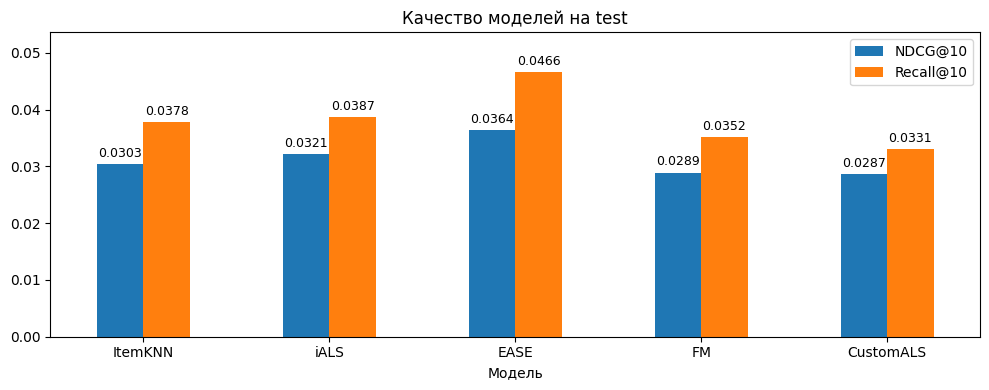

In [34]:
ax = result[['NDCG@10', 'Recall@10']].plot.bar(figsize=(10, 4), rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)

ax.margins(y=0.15)
plt.title('Качество моделей на test')
plt.tight_layout()
plt.show()


6. Выводы

Лучший результат у EASE с регуляризацией 300: NDCG@10 = 0,036391, Recall@10 = 0,046606.

CustomALS уступила iALS: NDCG@10 = 0,028686 против 0,032114. Настройки тоже различаются, поэтому нельзя объяснить разницу только новой целью.

FM уступила EASE и iALS. Бренд известен у 59% товаров. Без сравнения FM с признаками и без них нельзя сказать, насколько признаки помогли.

Данные только за один месяц из одного магазина. Выбраны активные пользователи и популярные товары. Новых пользователей и повторные покупки не проверяли. Для каждой модели пробовали только два набора настроек. Товар в корзине не всегда покупают, а цена может измениться. Recall@10 низкий.